# 02 – Explore Steel Plates Faults (real data)

Data: UCI Steel Plates Faults – Buscema, Terzi & Tastle (2010), CC BY 4.0, https://doi.org/10.24432/C5J88N
(see `data/steel_plates/README.md`). One row = one surface defect detected on a steel plate.

Questions: How big and clean is the data? How imbalanced are the 7 fault types? Which features separate them?
How good is a trivial baseline – and does model **confidence** separate right from wrong predictions
(the idea behind the threshold what-if)?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("..").resolve().parent / "data" / "steel_plates"
columns = (DATA / "Faults27x7_var").read_text().split()
df = pd.read_csv(DATA / "Faults.NNA", sep="\t", header=None, names=columns)

CLASSES = columns[-7:]
FEATURES = columns[:-7]
# One-hot fault columns -> one label column (exactly one fault per row).
df["fault"] = df[CLASSES].idxmax(axis=1)
print(df.shape, "| missing values:", df.isna().sum().sum(), "| rows with != 1 fault:", (df[CLASSES].sum(axis=1) != 1).sum())
df[FEATURES].describe().T[["mean", "std", "min", "max"]].round(2)

(1941, 35) | missing values: 0 | rows with != 1 fault: 0


,mean,std,min,max
X_Minimum,571.14,520.69,0.00,1705.00
X_Maximum,617.96,497.63,4.00,1713.00
Y_Minimum,1650684.87,1774578.41,6712.00,12987661.00
Y_Maximum,1650738.71,1774590.09,6724.00,12987692.00
Pixels_Areas,1893.88,5168.46,2.00,152655.00
X_Perimeter,111.86,301.21,2.00,10449.00
Y_Perimeter,82.97,426.48,1.00,18152.00
Sum_of_Luminosity,206312.15,512293.59,250.00,11591414.00
Minimum_of_Luminosity,84.55,32.13,0.00,203.00
Maximum_of_Luminosity,130.19,18.69,37.00,253.00


## Class balance

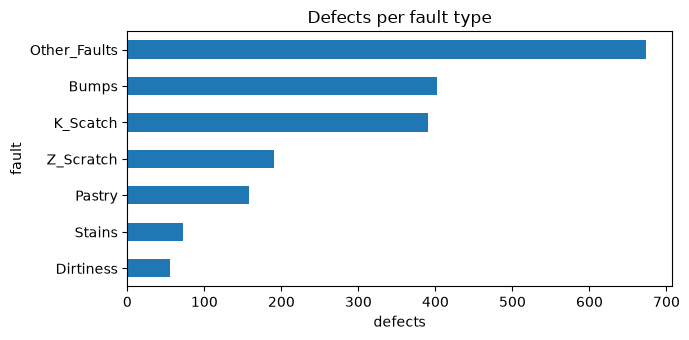

fault
Other_Faults    34.7
Bumps           20.7
K_Scatch        20.1
Z_Scratch        9.8
Pastry           8.1
Stains           3.7
Dirtiness        2.8
Name: percent, dtype: float64

In [2]:
counts = df["fault"].value_counts()
ax = counts.plot.barh(figsize=(7, 3.5), title="Defects per fault type")
ax.invert_yaxis(); ax.set_xlabel("defects")
plt.tight_layout(); plt.show()
(counts / len(df) * 100).round(1).rename("percent")

## Plate context: steel type and thickness
`TypeOfSteel_A300` and `TypeOfSteel_A400` are one-hot (exactly one is 1) → one of them is redundant for the model.

In [3]:
print("A300 + A400 == 1 for every row:", (df["TypeOfSteel_A300"] + df["TypeOfSteel_A400"] == 1).all())
pd.crosstab(df["fault"], df["TypeOfSteel_A300"].map({1: "A300", 0: "A400"}), normalize="index").round(2)

A300 + A400 == 1 for every row: True


TypeOfSteel_A300,A300,A400
fault,,
Bumps,0.69,0.31
Dirtiness,0.16,0.84
K_Scatch,0.00,1.00
Other_Faults,0.40,0.60
Pastry,0.31,0.69
Stains,0.01,0.99
Z_Scratch,0.91,0.09


## Feature distributions per fault type

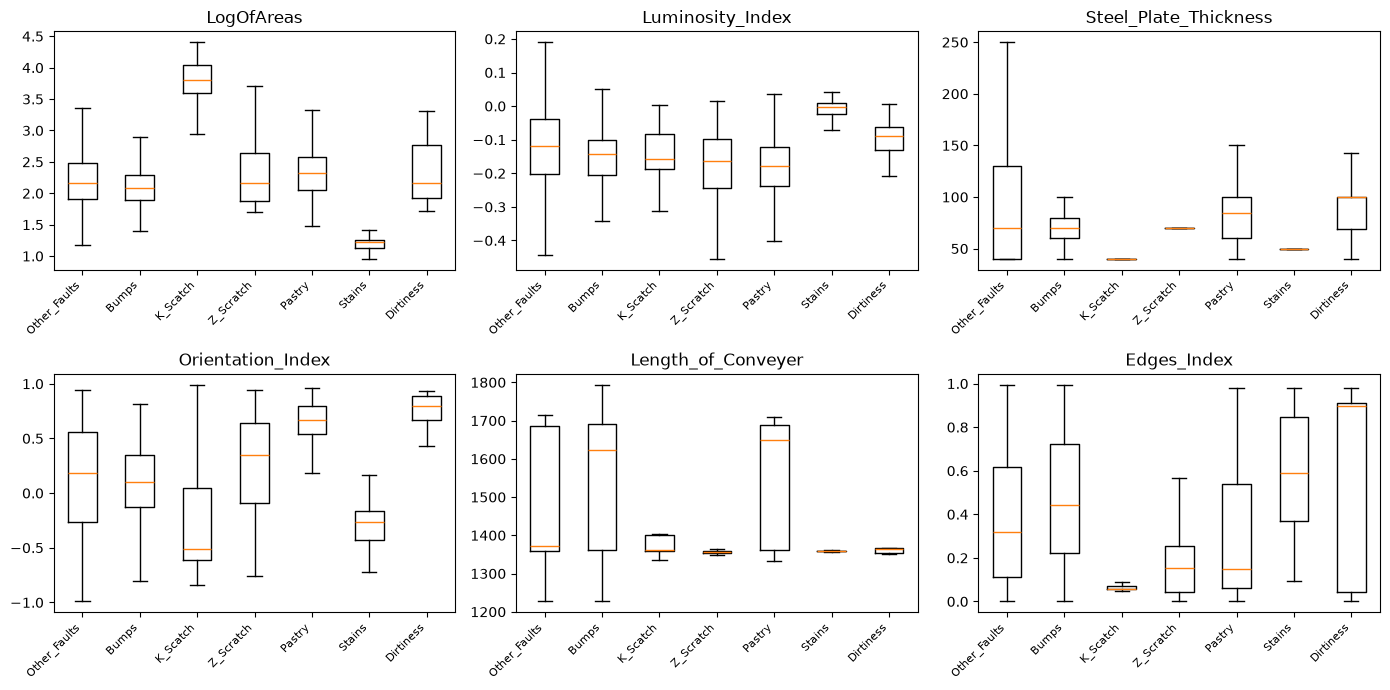

In [4]:
show = ["LogOfAreas", "Luminosity_Index", "Steel_Plate_Thickness", "Orientation_Index",
        "Length_of_Conveyer", "Edges_Index"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
order = counts.index
for ax, col in zip(axes.flat, show):
    ax.boxplot([df.loc[df["fault"] == c, col] for c in order], showfliers=False)
    ax.set_xticks(range(1, len(order) + 1), order, rotation=45, ha="right", fontsize=8)
    ax.set_title(col)
plt.tight_layout(); plt.show()

## Correlations between features
Strongly correlated groups (e.g. area/perimeter/log-area) carry overlapping information.

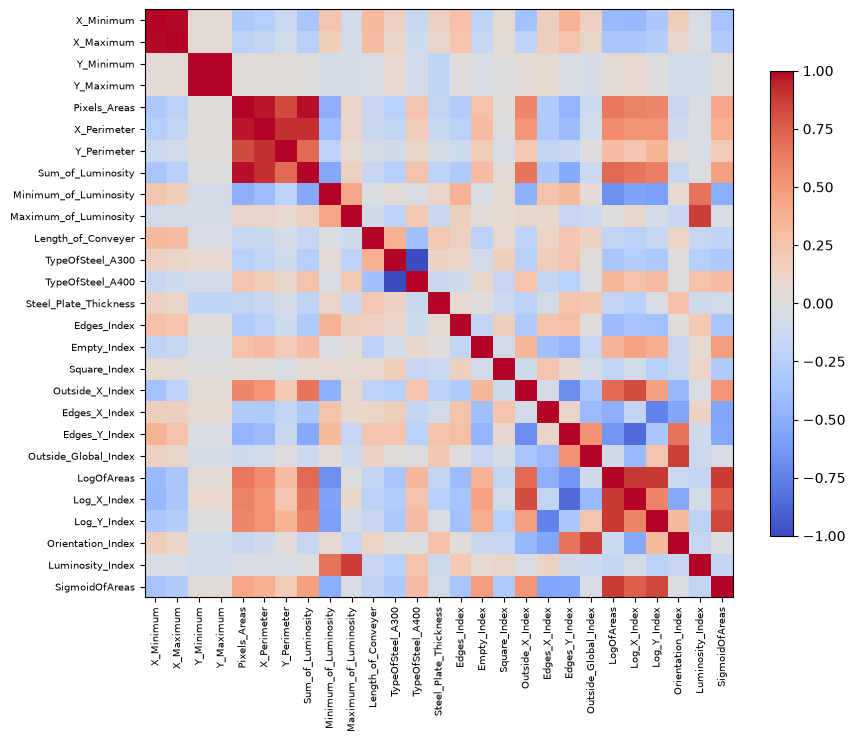

TypeOfSteel_A300  TypeOfSteel_A400    -1.000
Y_Minimum         Y_Maximum            1.000
X_Minimum         X_Maximum            0.988
Pixels_Areas      Sum_of_Luminosity    0.979
                  X_Perimeter          0.967
X_Perimeter       Sum_of_Luminosity    0.913
                  Y_Perimeter          0.912
dtype: float64

In [5]:
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=7)
ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=7)
fig.colorbar(im, shrink=0.7); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False).round(3)

## Baseline and a quick model preview
Stratified 80/20 split (keeps the class shares in train and test), seed 42.
Baseline = always predict the most frequent class. The RandomForest here is only a **preview** –
real training, tuning and saving happen in Stage 13 (`train.py`).

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split

X, y = df[FEATURES], df["fault"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

for name, clf in [("baseline (most frequent)", DummyClassifier(strategy="most_frequent")),
                  ("random forest (preview)", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))]:
    pred = clf.fit(X_train, y_train).predict(X_test)
    print(f"{name:26s} accuracy {accuracy_score(y_test, pred):.3f}   macro F1 {f1_score(y_test, pred, average='macro'):.3f}")

rf = clf
print()
print(classification_report(y_test, pred, digits=2))

baseline (most frequent)   accuracy 0.347   macro F1 0.074


random forest (preview)    accuracy 0.802   macro F1 0.812

              precision    recall  f1-score   support

       Bumps       0.74      0.70      0.72        81
   Dirtiness       0.90      0.82      0.86        11
    K_Scatch       0.97      0.91      0.94        78
Other_Faults       0.72      0.84      0.78       135
      Pastry       0.70      0.50      0.58        32
      Stains       0.92      0.86      0.89        14
   Z_Scratch       0.97      0.87      0.92        38

    accuracy                           0.80       389
   macro avg       0.85      0.79      0.81       389
weighted avg       0.81      0.80      0.80       389



## Does confidence separate right from wrong? (basis for the threshold what-if)
Confidence = highest class probability of the model. If correct predictions have clearly higher confidence than
wrong ones, a threshold can send the uncertain defects to manual review and keep the auto-classified ones accurate.

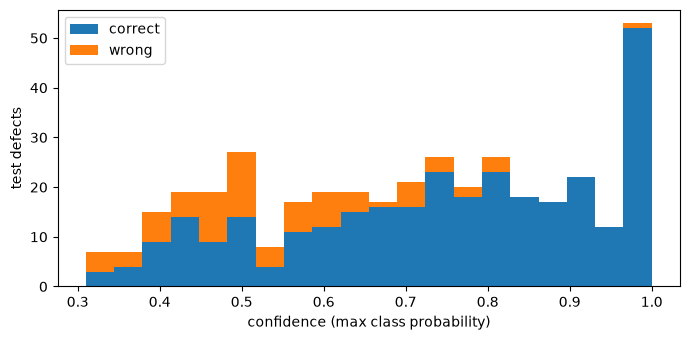

,threshold,auto_classified_%,manual_review_%,error_rate_in_auto_%
0,0.0,100.0,0.0,19.8
1,0.4,94.1,5.9,17.8
2,0.5,79.4,20.6,13.9
3,0.6,67.6,32.4,8.7
4,0.7,54.2,45.8,6.2
5,0.8,37.5,62.5,2.7
6,0.9,21.3,78.7,1.2


In [7]:
proba = rf.predict_proba(X_test)
confidence = proba.max(axis=1)
correct = rf.classes_[proba.argmax(axis=1)] == y_test.to_numpy()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist([confidence[correct], confidence[~correct]], bins=20, label=["correct", "wrong"], stacked=True)
ax.set_xlabel("confidence (max class probability)"); ax.set_ylabel("test defects"); ax.legend()
plt.tight_layout(); plt.show()

rows = []
for t in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    auto = confidence >= t
    rows.append({"threshold": t,
                 "auto_classified_%": round(100 * auto.mean(), 1),
                 "manual_review_%": round(100 * (~auto).mean(), 1),
                 "error_rate_in_auto_%": round(100 * (~correct[auto]).mean(), 1) if auto.any() else None})
pd.DataFrame(rows)

## Findings
- Clean: 1,941 defects, 27 features, no missing values, exactly one fault per row.
- Imbalanced: Other_Faults 34.7 % … Dirtiness 2.8 % → stratified split, report macro F1 and per-class results.
- `TypeOfSteel_A300` = 1 − `TypeOfSteel_A400` (drop one). Steel type is very telling: K_Scatch and Stains occur almost
  only on A400, Z_Scratch 91 % on A300.
- Highly correlated groups: X/Y min–max pairs, area ↔ luminosity sum ↔ perimeters.
- Baseline (most frequent class): accuracy 0.347, macro F1 0.074. RandomForest preview: accuracy 0.802, macro F1 0.812.
  Hardest class: Pastry (recall 0.50); Bumps vs. Other_Faults get confused.
- **Confidence separates right from wrong** → threshold what-if makes sense: at 0.7, 54 % auto-classified with 6.2 %
  errors (vs. 19.8 % errors without threshold), 46 % to manual review.
- To check in Stage 13: position features (`X/Y_Minimum/Maximum`) may let the model memorise plates (leakage) –
  compare a model without them.